# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Rayhan Lutfi Hakim | 5054251043 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
sns.set_style('whitegrid')
RS = 42


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv')
print('Shape:', df.shape)
df.info()
display(df.describe().T)
print('Missing value:\n', df.isnull().sum())
print('Baris duplikat:', df.duplicated().sum())
print('Kolom kosong seluruhnya:', df.columns[df.isnull().all()].tolist())
display(df.head())


Shape: (7050, 16)
<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), str(2)
me

,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0


Missing value:
 status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64
Baris duplikat: 0
Kolom kosong seluruhnya: ['Column1', 'Column2', 'Column3', 'Column4']


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


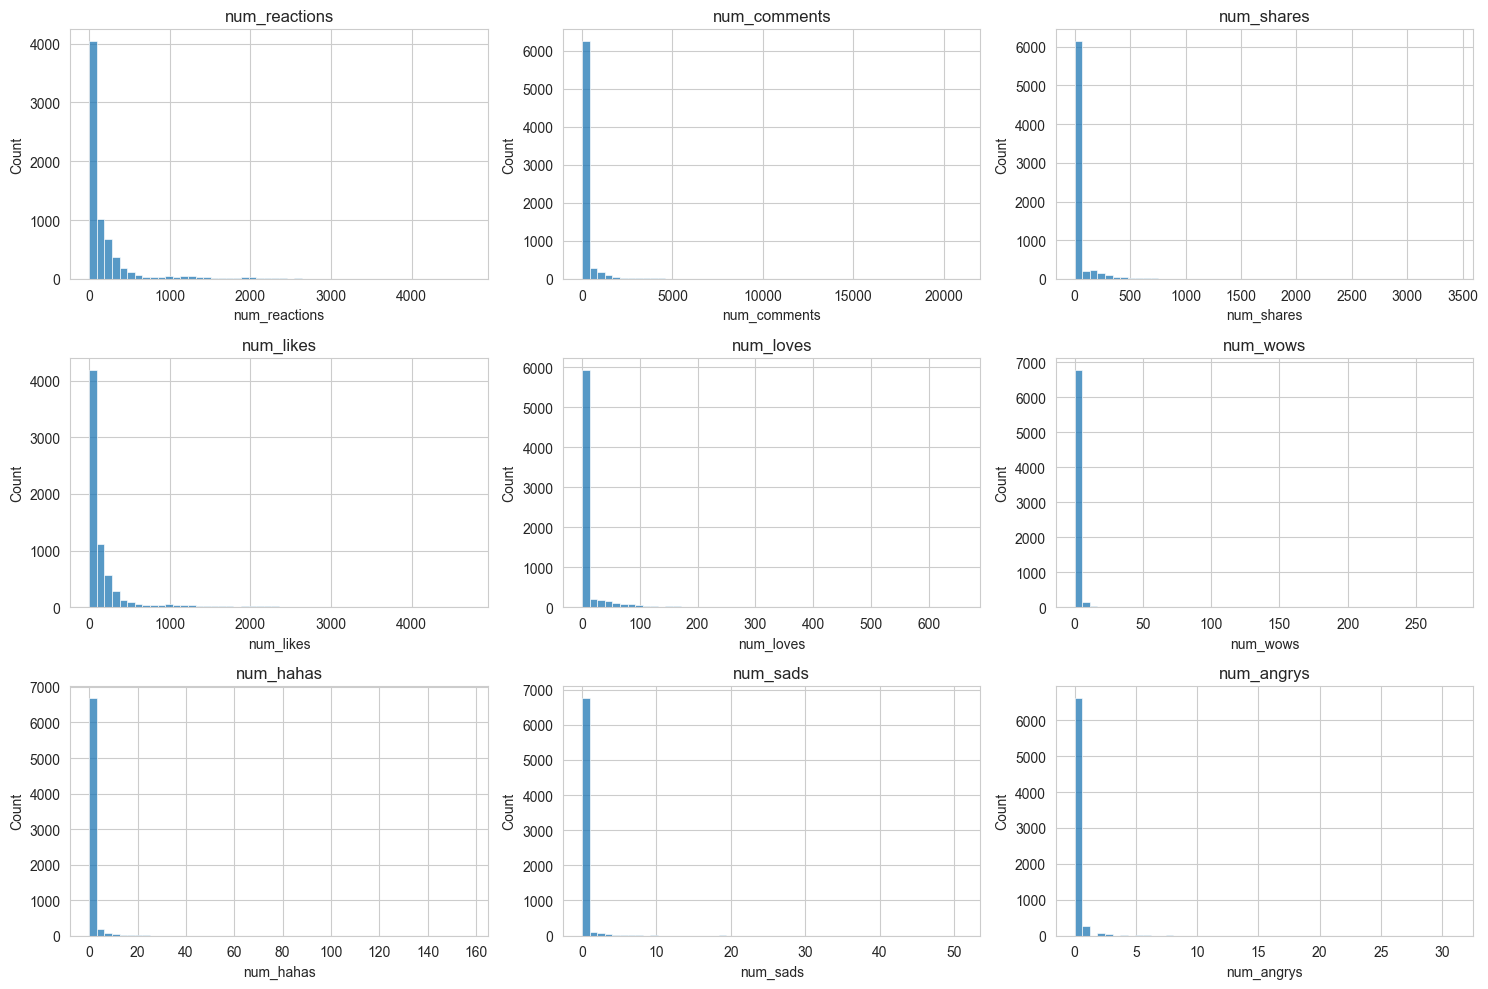

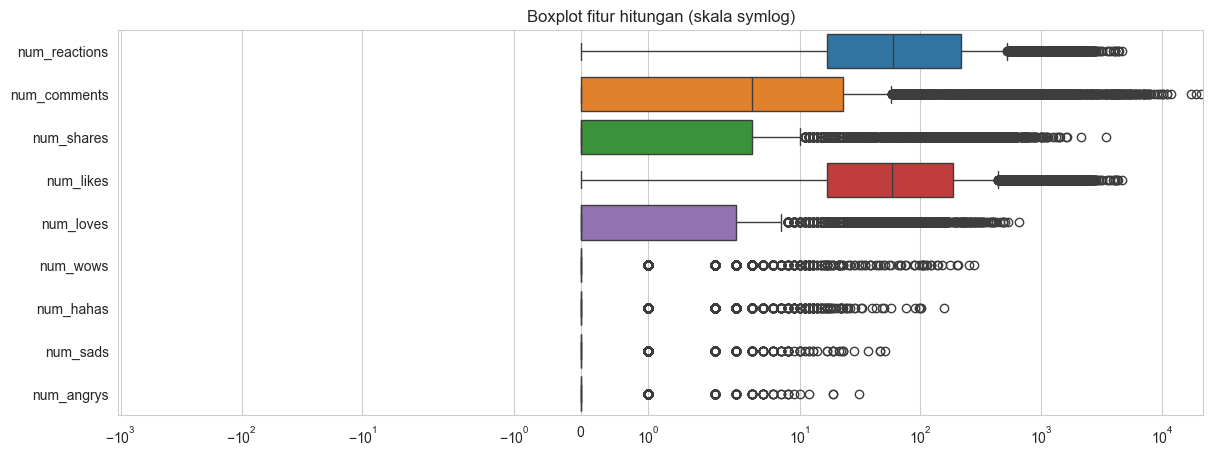

Skewness:


num_reactions     3.738452
num_comments      9.028850
num_shares        7.099332
num_likes         3.919128
num_loves         6.004845
num_wows         18.246813
num_hahas        20.305741
num_sads         17.578868
num_angrys       19.507129
dtype: float64

Proporsi nilai nol:


num_reactions    0.017163
num_comments     0.300567
num_shares       0.554752
num_likes        0.017872
num_loves        0.600000
num_wows         0.752908
num_hahas        0.839149
num_sads         0.913901
num_angrys       0.940000
dtype: float64

Nilai maksimum:


num_reactions     4710
num_comments     20990
num_shares        3424
num_likes         4710
num_loves          657
num_wows           278
num_hahas          157
num_sads            51
num_angrys          31
dtype: int64

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
count_cols = ['num_reactions','num_comments','num_shares','num_likes','num_loves','num_wows','num_hahas','num_sads','num_angrys']
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), count_cols):
    sns.histplot(df[c], bins=50, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()
plt.figure(figsize=(14, 5))
sns.boxplot(data=df[count_cols], orient='h')
plt.xscale('symlog'); plt.title('Boxplot fitur hitungan (skala symlog)'); plt.show()
print('Skewness:'); display(df[count_cols].skew())
print('Proporsi nilai nol:'); display((df[count_cols] == 0).mean())
print('Nilai maksimum:'); display(df[count_cols].max())



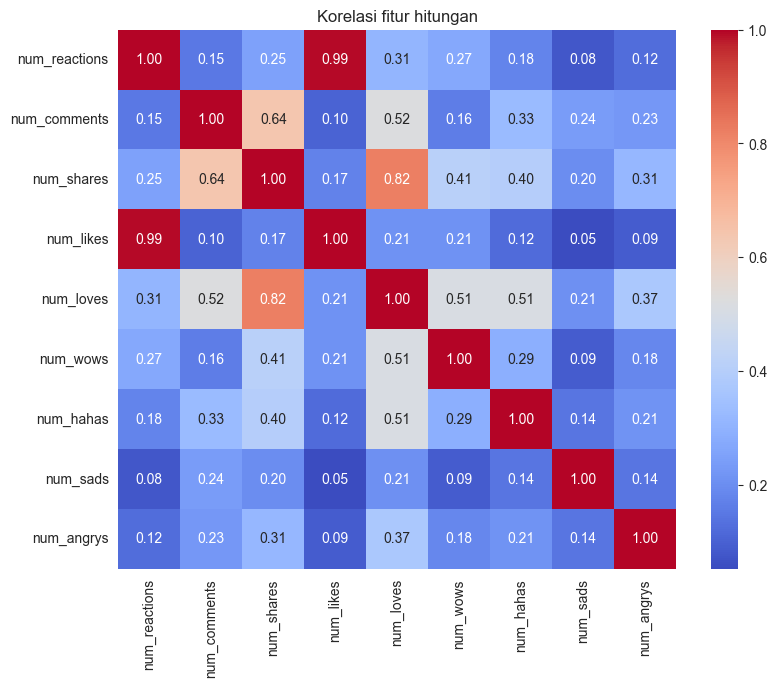

num_reactions == jumlah semua reaksi? 0.9987234042553191


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(9, 7))
sns.heatmap(df[count_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi fitur hitungan'); plt.show()
print('num_reactions == jumlah semua reaksi?',
      (df['num_reactions'] == df[['num_likes','num_loves','num_wows','num_hahas','num_sads','num_angrys']].sum(axis=1)).mean())


,jumlah_posting,proporsi_emoji
year,,
2012,589,0.000000
2013,500,0.000000
2014,233,0.000000
2015,337,0.000000
2016,588,0.680272
2017,2253,0.541944
2018,2550,0.577647


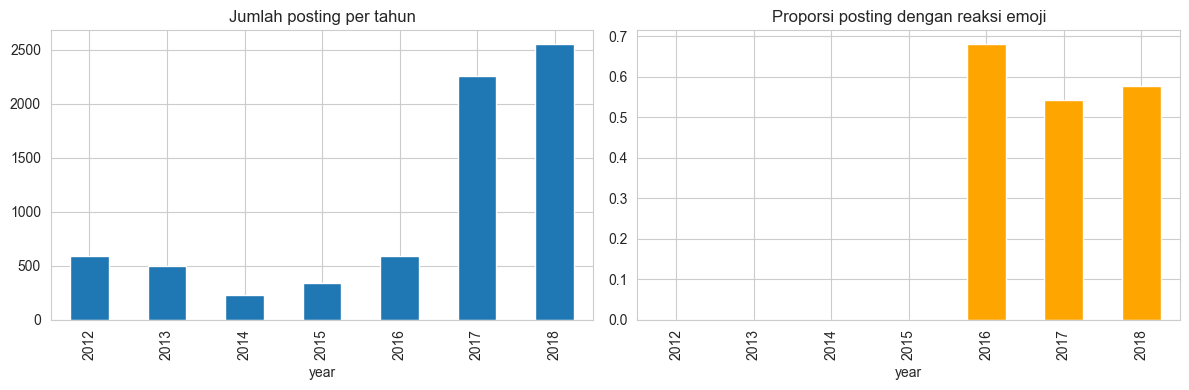

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'])
df['year'] = df['status_published'].dt.year
emoji_cols = ['num_loves','num_wows','num_hahas','num_sads','num_angrys']
df['has_emoji'] = (df[emoji_cols].sum(axis=1) > 0)
yearly = df.groupby('year').agg(jumlah_posting=('status_id','count'), proporsi_emoji=('has_emoji','mean'))
display(yearly)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
yearly['jumlah_posting'].plot(kind='bar', ax=ax[0], title='Jumlah posting per tahun')
yearly['proporsi_emoji'].plot(kind='bar', ax=ax[1], title='Proporsi posting dengan reaksi emoji', color='orange')
plt.tight_layout(); plt.show()


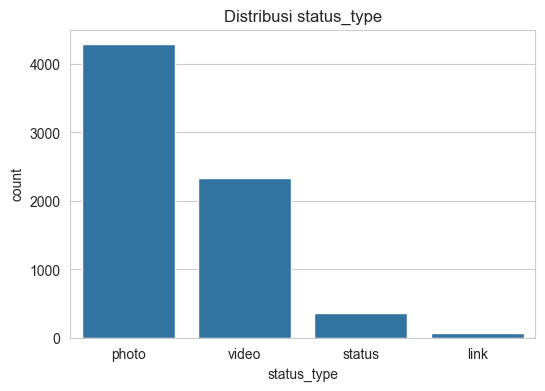

,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='status_type', order=df['status_type'].value_counts().index)
plt.title('Distribusi status_type'); plt.show()
display(df.groupby('status_type')[['num_likes','num_comments','num_shares']].median())


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [7]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
df = df.dropna(axis=1, how='all')
print('Kolom tersisa:', df.columns.tolist())
# status_id selalu unik, jadi baris dengan angka sama tetap posting berbeda (tidak dihapus)
print('Duplikat status_id:', df['status_id'].duplicated().sum())
print('Duplikat seluruh kolom:', df.duplicated().sum())
print('Missing value:', df.isnull().sum().sum())
# Outlier ekstrem tidak dihapus, ditangani lewat transformasi log1p
print('Rasio max / persentil 99 per fitur:')
display((df[count_cols].max() / df[count_cols].quantile(0.99).replace(0, np.nan)).round(1))
print('Jumlah baris:', len(df))


Kolom tersisa: ['status_id', 'status_type', 'status_published', 'num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys', 'year', 'has_emoji']
Duplikat status_id: 0
Duplikat seluruh kolom: 0
Missing value: 0
Rasio max / persentil 99 per fitur:


num_reactions     2.0
num_comments      4.8
num_shares        5.6
num_likes         2.1
num_loves         3.3
num_wows         17.4
num_hahas        13.1
num_sads         10.2
num_angrys       10.3
dtype: float64

Jumlah baris: 7050


In [8]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
meta = df[['status_type','status_published']].copy()
df['num_other_emoji'] = df[['num_wows','num_hahas','num_sads','num_angrys']].sum(axis=1)
features = ['num_comments','num_shares','num_likes','num_loves','num_other_emoji']
X = df[features].copy()
print('Proporsi nol:'); display((X == 0).mean())
display(X.describe().T)


Proporsi nol:


num_comments       0.300567
num_shares         0.554752
num_likes          0.017872
num_loves          0.600000
num_other_emoji    0.685248
dtype: float64

,count,mean,std,min,25%,50%,75%,max
num_comments,7050.0,224.356028,889.636820,0.0,0.0,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.0,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.0,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.0,0.0,3.00,657.0
num_other_emoji,7050.0,2.342695,11.076797,0.0,0.0,0.0,1.00,286.0


**Fitur yang dipilih untuk clustering:** (isi daftar fitur yang kalian pilih beserta alasannya, termasuk keputusan terhadap kolom yang redundan atau banyak bernilai nol)

**Fitur yang dipilih untuk clustering:** `num_comments`, `num_shares`, `num_likes`, `num_loves`, `num_other_emoji`. `num_reactions` dibuang karena merupakan penjumlahan likes + loves + emoji lain (redundan, akan membobot ganda jarak). `status_id` dibuang karena hanya identitas. `num_wows`, `num_hahas`, `num_sads`, `num_angrys` sebagian besar bernilai nol, sehingga digabung menjadi `num_other_emoji`. `status_type` dan `status_published` dipisahkan hanya untuk interpretasi.


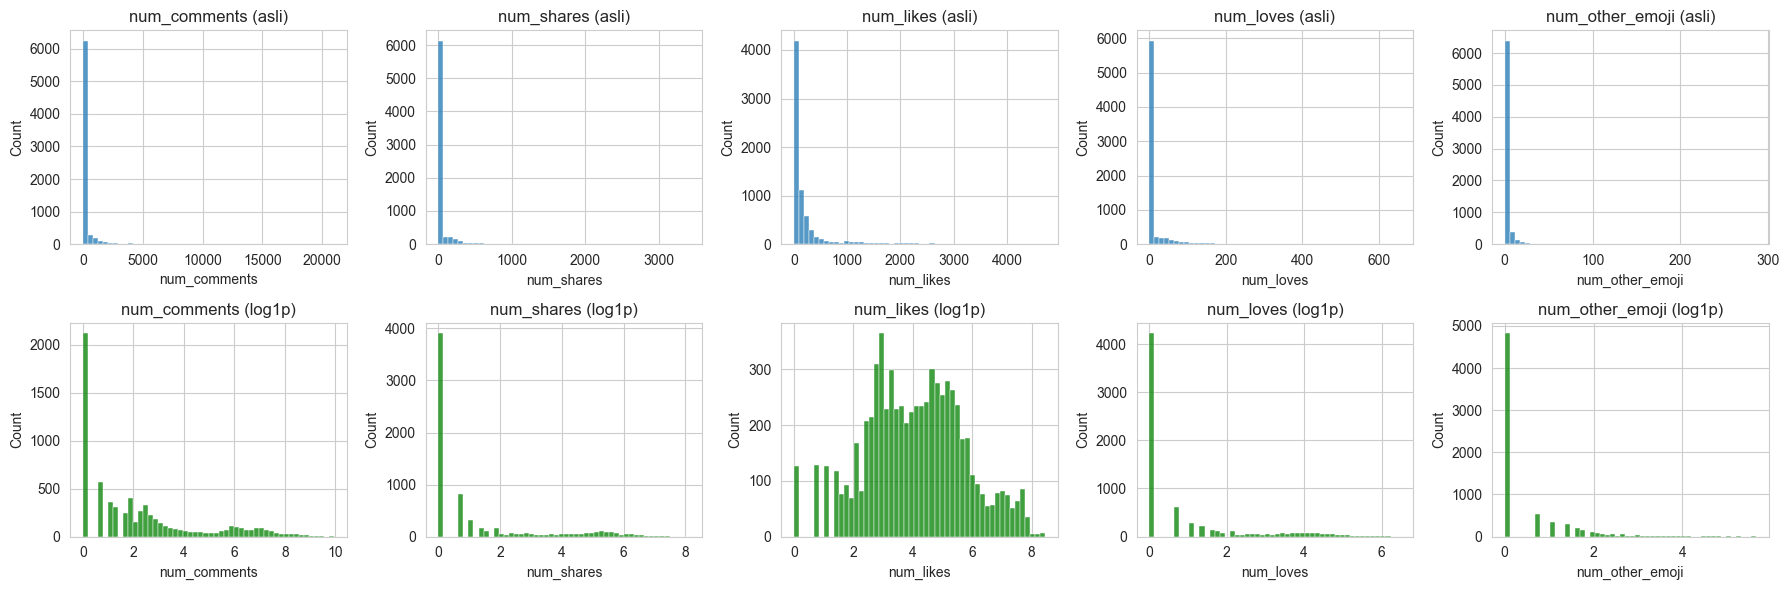

Skewness sebelum:


num_comments        9.028850
num_shares          7.099332
num_likes           3.919128
num_loves           6.004845
num_other_emoji    13.881876
dtype: float64

Skewness sesudah:


num_comments       1.037503
num_shares         1.526020
num_likes         -0.014455
num_loves          1.503784
num_other_emoji    1.940864
dtype: float64

In [9]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X)
fig, axes = plt.subplots(2, len(features), figsize=(18, 6))
for i, c in enumerate(features):
    sns.histplot(X[c], bins=50, ax=axes[0, i]); axes[0, i].set_title(f'{c} (asli)')
    sns.histplot(X_log[c], bins=50, ax=axes[1, i], color='green'); axes[1, i].set_title(f'{c} (log1p)')
plt.tight_layout(); plt.show()
print('Skewness sebelum:'); display(X.skew())
print('Skewness sesudah:'); display(X_log.skew())


In [10]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
X_raw = X.values
X_raw_scaled = StandardScaler().fit_transform(X)
X_log_scaled = StandardScaler().fit_transform(X_log)
print(X_raw.shape, X_raw_scaled.shape, X_log_scaled.shape)


(7050, 5) (7050, 5) (7050, 5)


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [11]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
K_TEST = 3
km_raw = KMeans(n_clusters=K_TEST, random_state=RS, n_init=10).fit(X_raw)
km_raw_scaled = KMeans(n_clusters=K_TEST, random_state=RS, n_init=10).fit(X_raw_scaled)
km_log_scaled = KMeans(n_clusters=K_TEST, random_state=RS, n_init=10).fit(X_log_scaled)


In [12]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
res = {}
for name, m in [('X_raw', km_raw), ('X_raw_scaled', km_raw_scaled), ('X_log_scaled', km_log_scaled)]:
    res[name] = {'ukuran_cluster': np.bincount(m.labels_).tolist(),
                 'silhouette (di X_log_scaled)': silhouette_score(X_log_scaled, m.labels_)}
display(pd.DataFrame(res).T)
print('Varians tiap fitur (tanpa scaling):'); display(X.var().round(1))
print('Proporsi varians per fitur:'); display((X.var() / X.var().sum()).round(4))


,ukuran_cluster,silhouette (di X_log_scaled)
X_raw,"[6430, 137, 483]",0.296657
X_raw_scaled,"[6368, 292, 390]",0.246179
X_log_scaled,"[3654, 1168, 2228]",0.430403


Varians tiap fitur (tanpa scaling):


num_comments       791453.7
num_shares          17318.6
num_likes          202025.4
num_loves            1597.8
num_other_emoji       122.7
dtype: float64

Proporsi varians per fitur:


num_comments       0.7817
num_shares         0.0171
num_likes          0.1995
num_loves          0.0016
num_other_emoji    0.0001
dtype: float64

## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
K_RANGE = range(2, 11)
inertias = []
for k in K_RANGE:
    inertias.append(KMeans(n_clusters=k, random_state=RS, n_init=10).fit(X_log_scaled).inertia_)
print(dict(zip(K_RANGE, np.round(inertias, 1))))


{2: np.float64(15240.5), 3: np.float64(10302.5), 4: np.float64(8539.7), 5: np.float64(7468.3), 6: np.float64(6465.9), 7: np.float64(5843.5), 8: np.float64(5369.2), 9: np.float64(4941.2), 10: np.float64(4642.2)}


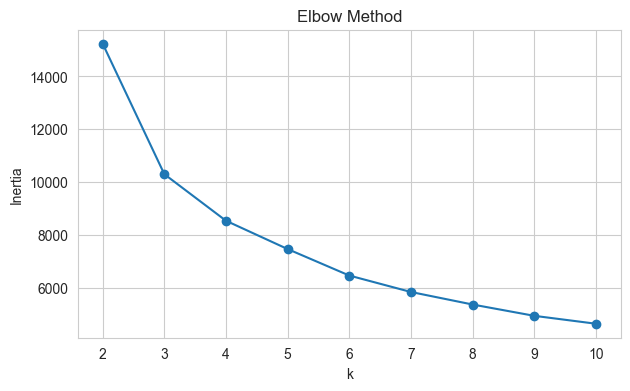

kneed tidak terpasang; gunakan pengamatan visual.
Penurunan inertia (%): [32.4 17.1 12.5 13.4  9.6  8.1  8.   6.1]


In [14]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(7, 4))
plt.plot(list(K_RANGE), inertias, 'o-')
plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('Elbow Method'); plt.show()
try:
    from kneed import KneeLocator
    kl = KneeLocator(list(K_RANGE), inertias, curve='convex', direction='decreasing')
    print('Elbow (kneed):', kl.elbow)
except ImportError:
    print('kneed tidak terpasang; gunakan pengamatan visual.')
print('Penurunan inertia (%):', np.round(-np.diff(inertias) / np.array(inertias[:-1]) * 100, 1))


## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [15]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil_scores = []
for k in K_RANGE:
    lbl = KMeans(n_clusters=k, random_state=RS, n_init=10).fit_predict(X_log_scaled)
    sil_scores.append(silhouette_score(X_log_scaled, lbl))
print(dict(zip(K_RANGE, np.round(sil_scores, 4))))


{2: np.float64(0.5826), 3: np.float64(0.4304), 4: np.float64(0.41), 5: np.float64(0.3962), 6: np.float64(0.3021), 7: np.float64(0.309), 8: np.float64(0.3085), 9: np.float64(0.3016), 10: np.float64(0.2962)}


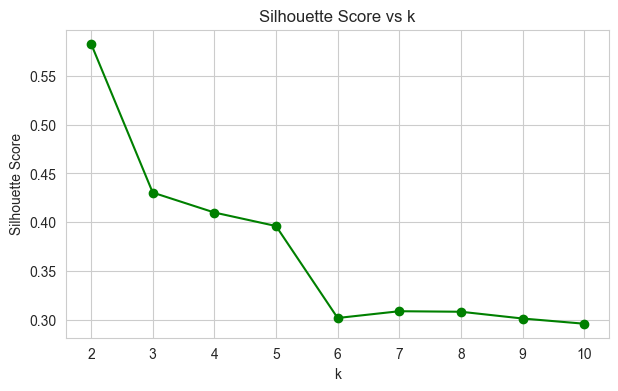

k terbaik menurut Silhouette: 2


In [16]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(7, 4))
plt.plot(list(K_RANGE), sil_scores, 'o-', color='green')
plt.xlabel('k'); plt.ylabel('Silhouette Score'); plt.title('Silhouette Score vs k'); plt.show()
print('k terbaik menurut Silhouette:', list(K_RANGE)[int(np.argmax(sil_scores))])


**Pilihan k untuk K-Means:** (isi nilai k yang kalian pilih beserta alasan singkatnya)

Jawabannya adalah 2, karena dari hasil silhouette yang terbaik adalah 2.

## 3.4 Model K-Means Final

In [17]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
K_BEST = 3   # sesuaikan dengan hasil Elbow + Silhouette
kmeans = KMeans(n_clusters=K_BEST, random_state=RS, n_init=10).fit(X_log_scaled)
labels_km = kmeans.labels_
print(pd.Series(labels_km).value_counts().sort_index())


0    3654
1    1168
2    2228
Name: count, dtype: int64


In [18]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
prof_km = X.copy(); prof_km['cluster'] = labels_km
display(prof_km.groupby('cluster').median().assign(jumlah=prof_km.groupby('cluster').size()))
display(prof_km.groupby('cluster').mean().round(1))


,num_comments,num_shares,num_likes,num_loves,num_other_emoji,jumlah
cluster,,,,,,
0,0.0,0.0,18.0,0.0,0.0,3654
1,677.0,169.5,179.5,50.0,5.0,1168
2,11.0,1.0,206.0,1.0,0.0,2228


,num_comments,num_shares,num_likes,num_loves,num_other_emoji
cluster,,,,,
0,2.2,0.5,23.1,0.1,0.1
1,1293.9,230.3,349.0,71.3,10.8
2,28.0,5.0,459.7,2.7,1.6


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [19]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z = linkage(X_log_scaled, method='ward')
print(Z.shape)

(7049, 4)


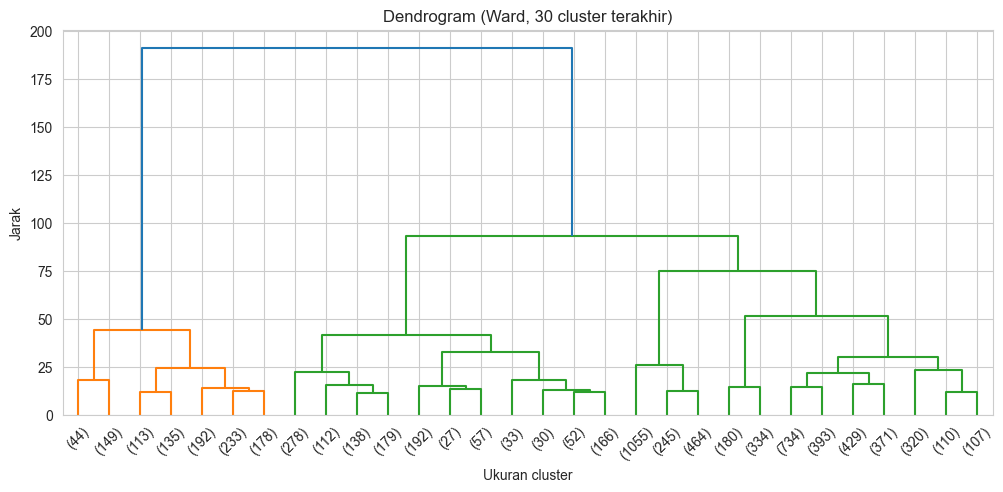

Jarak 10 penggabungan terakhir: [ 24.1  26.1  29.9  32.6  41.5  44.3  51.6  74.6  93.3 191.2]


In [20]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrogram (Ward, 30 cluster terakhir)'); plt.xlabel('Ukuran cluster'); plt.ylabel('Jarak')
plt.show()
print('Jarak 10 penggabungan terakhir:', np.round(Z[-10:, 2], 1))

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [21]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkages = ['ward', 'complete', 'average', 'single']
hc_labels = {}
for lk in linkages:
    hc_labels[lk] = AgglomerativeClustering(n_clusters=K_BEST, linkage=lk).fit_predict(X_log_scaled)


In [22]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
rows = []
for lk in linkages:
    rows.append({'linkage': lk, 'silhouette': silhouette_score(X_log_scaled, hc_labels[lk]),
                 'ukuran_cluster': np.bincount(hc_labels[lk]).tolist()})
display(pd.DataFrame(rows).set_index('linkage'))


,silhouette,ukuran_cluster
linkage,,
ward,0.400085,"[4742, 1044, 1264]"
complete,0.498629,"[1374, 200, 5476]"
average,0.550359,"[1122, 5899, 29]"
single,0.348623,"[7048, 1, 1]"


**Pilihan linkage untuk Hierarchical Clustering:** (isi linkage yang kalian pilih beserta alasan singkatnya)

Ward karena ukuran cluster yang dihasilkan tidak terlalu ada yang dominan sehingga menghasilkan hasil yang seimbang.

## 4.3 Model Hierarchical Clustering Final

In [23]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
LINK = 'ward'   # sesuaikan dengan hasil tabel di atas
hc = AgglomerativeClustering(n_clusters=K_BEST, linkage=LINK).fit(X_log_scaled)
labels_hc = hc.labels_
print(pd.Series(labels_hc).value_counts().sort_index())


0    4742
1    1044
2    1264
Name: count, dtype: int64


In [24]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
prof_hc = X.copy(); prof_hc['cluster'] = labels_hc
display(prof_hc.groupby('cluster').median().assign(jumlah=prof_hc.groupby('cluster').size()))
display(prof_hc.groupby('cluster').mean().round(1))


,num_comments,num_shares,num_likes,num_loves,num_other_emoji,jumlah
cluster,,,,,,
0,1.0,0.0,26.0,0.0,0.0,4742
1,809.5,192.5,166.5,55.0,4.0,1044
2,12.0,1.0,169.5,3.0,2.0,1264


,num_comments,num_shares,num_likes,num_loves,num_other_emoji
cluster,,,,,
0,5.8,1.2,170.2,0.4,0.0
1,1427.9,254.5,277.4,77.6,10.4
2,50.3,8.4,331.7,5.5,4.5


# 5. Evaluasi Model

In [25]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
def ev(lbl):
    return {'Silhouette': silhouette_score(X_log_scaled, lbl),
            'Davies-Bouldin': davies_bouldin_score(X_log_scaled, lbl),
            'Calinski-Harabasz': calinski_harabasz_score(X_log_scaled, lbl)}
display(pd.DataFrame({'K-Means': ev(labels_km), 'Hierarchical': ev(labels_hc)}).T)


,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,0.430403,0.957246,8532.105723
Hierarchical,0.400085,1.086619,6315.492758


Varians dijelaskan: [73.1  13.23] % | total 86.33 %


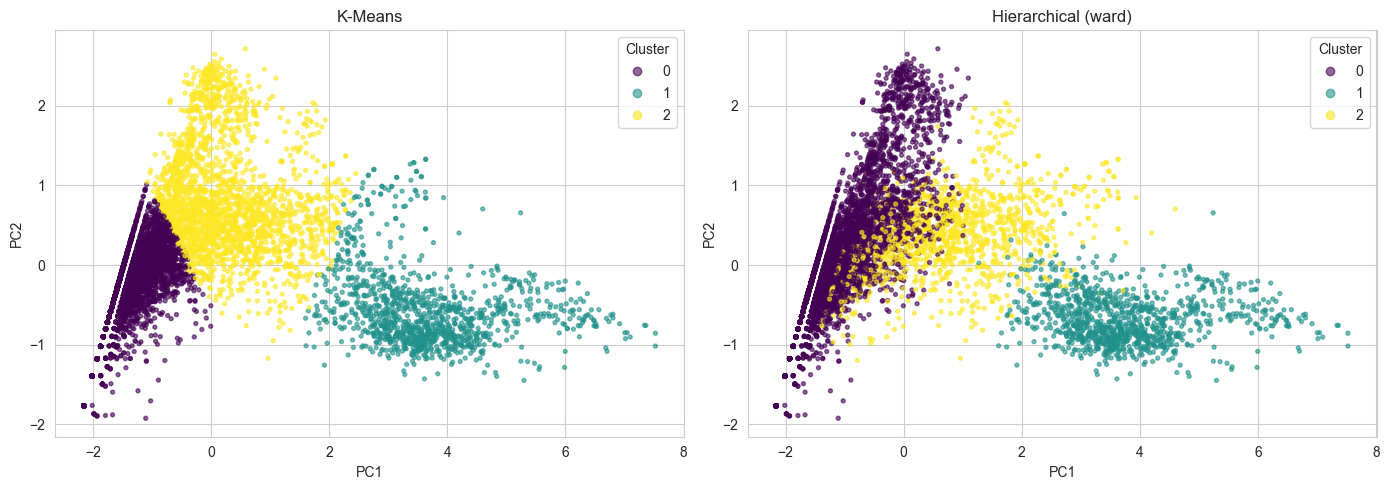

In [26]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=RS)
X_pca = pca.fit_transform(X_log_scaled)
print('Varians dijelaskan:', np.round(pca.explained_variance_ratio_ * 100, 2), '% | total', round(pca.explained_variance_ratio_.sum() * 100, 2), '%')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lbl, t in zip(axes, [labels_km, labels_hc], ['K-Means', f'Hierarchical ({LINK})']):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lbl, cmap='viridis', s=8, alpha=0.6)
    ax.set_title(t); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(*sc.legend_elements(), title='Cluster')
plt.tight_layout(); plt.show()


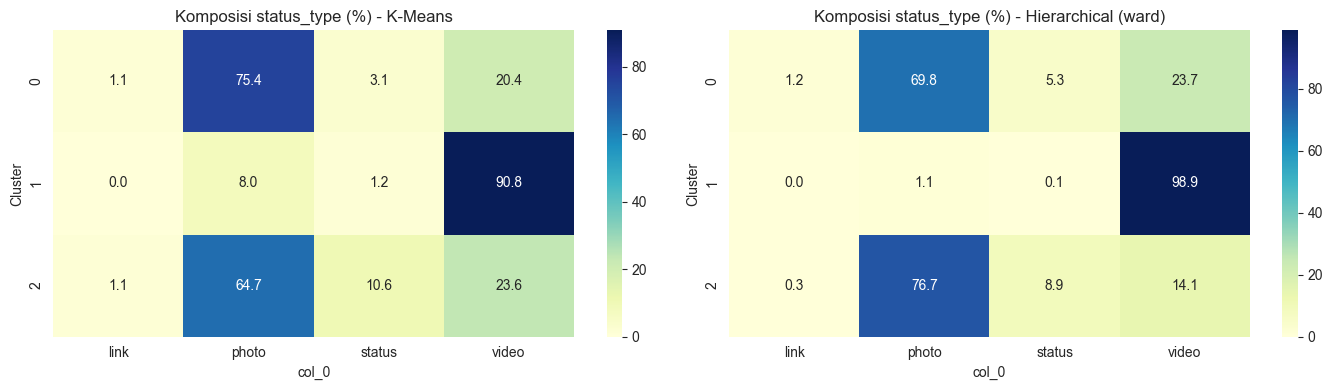

In [27]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, lbl, t in zip(axes, [labels_km, labels_hc], ['K-Means', f'Hierarchical ({LINK})']):
    ct = pd.crosstab(lbl, meta['status_type'].values, normalize='index') * 100
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax)
    ax.set_title(f'Komposisi status_type (%) - {t}'); ax.set_ylabel('Cluster')
plt.tight_layout(); plt.show()


# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

1. scaling memperbaiki masalah skala, log memperbaiki masalah bentuk distribusi dan outlier. Keduanya perlu dipakai bersama pada algoritma berbasis jarak.
2. Membuang beberaoa fitur yang didonminasi 0, membuang num_reactions.
3. Keduanya menghasilkan kesimpulan yang sama yaitu pada K=2 memiliki nilai tertinggi.
4. Ward karena ukuran cluster yang dihasilkan tidak terlalu ada yang dominan sehingga menghasilkan hasil yang seimbang. Bentuk cluster dari single link sendiri memiliki nilai yang sangat dominan dan sisanya bernilai 1.
5. Untuk hasilnya tidak terlalu signifikan perbedaannya, melihat dari matriks ke 2 model sama sama dominan menebak photo di cluster 0 dan 2 serta video di cluster 1. Hal tersebut terjadi karena  keduanya berbasis kriteria varians dan bekerja pada ruang fitur yang sama.
6. Cluster 0 dan 2: didominasi oleh photo, cluster 1: didominasi oleh video
7. kelebihan dan kekurangan K-Means: Cepat, sensitif terhadap outlier, berubah jika random_state beruabh, ceenteroid mudah di baca.
Kelebihan dan kekurangan Hierarichal: Dendogram untuk menunjukkan hierariki, Lambat dan boros, fleksible tergantung linkage.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

Kesimpulan dan saran yang dapat diambil adalah, harus menerapkan scaling log1p pada kedua model, jumlah cluster yang dihasilkan sama, coba DBSCAN (untuk outlier) atau Gaussian Mixture Model (untuk cluster yang tumpang tindih), Gunakan reduksi dimensi sebelum clustering.